In [1]:
import numpy as np
from sklearn.linear_model import LassoCV, Ridge, LinearRegression
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

In [2]:


file_path = "cleaned_equal_weighted_daily.csv"

# ---------- STEP 1: LOAD & INSPECT RAW ----------
if not Path(file_path).exists():
    raise FileNotFoundError(f"Can't find {file_path}")

# Try to sniff delimiter + handle possible BOM/encoding issues
df_raw = pd.read_csv(
    file_path,
    sep=None, engine="python",            # sniff delimiter
    dtype=str,                            # read everything as str first
    encoding="utf-8-sig",                 # tolerate BOM if present
)

print(f"[RAW] shape={df_raw.shape}")
print(f"[RAW] first 3 rows:\n{df_raw.head(3)}")
print(f"[RAW] columns:\n{list(df_raw.columns)}\n")

# ---------- STEP 2: STANDARDIZE COLUMN NAMES ----------
# Ensure first column is called "Date"
df_raw.rename(columns={df_raw.columns[0]: "Date"}, inplace=True)

# Trim whitespace in headers
df_raw.columns = [c.strip() for c in df_raw.columns]

# ---------- STEP 3: CLEAN STRINGS & MISSING ----------
# Strip whitespace in all cells
df = df_raw.applymap(lambda x: x.strip() if isinstance(x, str) else x)

# Normalize common missing tokens
na_like = {"", "NA", "NaN", "nan", "N/A", "null", "NULL", "-"}
df = df.replace(list(na_like), pd.NA)

# Replace sentinel missings (include a few variants)
sentinels = ["-99.99", "-999", "-999.0", "-999.00", "-99.9900"]
df = df.replace(sentinels, pd.NA)

[RAW] shape=(15602, 101)
[RAW] first 3 rows:
         Date Port_1 Port_2 Port_3 Port_4 Port_5 Port_6 Port_7 Port_8 Port_9  \
0  1963-07-02   0.36   0.27   0.49   0.31   0.67   0.13   0.79  -0.45   -0.1   
1  1963-07-03   0.74   0.77  -0.51   0.06   0.16   0.87   0.06   1.04   0.18   
2  1963-07-05   0.71   0.19    0.7   0.66   0.05  -0.44   0.58  -0.53   0.08   

   ... Port_91 Port_92 Port_93 Port_94 Port_95 Port_96 Port_97 Port_98  \
0  ...    0.81    0.87    1.16    0.67    0.59    0.35    0.78    0.96   
1  ...   -0.26     0.1    0.78    0.89    0.67     0.2    0.53    1.04   
2  ...    0.26    0.66    0.33    0.53    0.11    0.16    0.64    0.57   

  Port_99 Port_100  
0    0.92     0.88  
1    0.43     0.24  
2    0.31     0.73  

[3 rows x 101 columns]
[RAW] columns:
['Date', 'Port_1', 'Port_2', 'Port_3', 'Port_4', 'Port_5', 'Port_6', 'Port_7', 'Port_8', 'Port_9', 'Port_10', 'Port_11', 'Port_12', 'Port_13', 'Port_14', 'Port_15', 'Port_16', 'Port_17', 'Port_18', 'Port_19', 'Port

/tmp/ipykernel_1327960/877676055.py:28: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df = df_raw.applymap(lambda x: x.strip() if isinstance(x, str) else x)


In [3]:

# ---------- STEP 4: PARSE DATE ----------
# Some files may have YYYYMMDD as ints/strings; ensure length 8 before parsing
def parse_yyyymmdd(x):
    if pd.isna(x):
        return pd.NaT
    s = str(x).strip()
    # keep only digits in case of stray characters
    s = "".join(ch for ch in s if ch.isdigit())
    if len(s) != 8:
        return pd.NaT
    try:
        return pd.to_datetime(s, format="%Y%m%d", errors="coerce")
    except Exception:
        return pd.NaT

df["Date"] = df["Date"].apply(parse_yyyymmdd)

print(f"[AFTER DATE PARSE] non-null Date count: {df['Date'].notna().sum()}")
print(f"[AFTER DATE PARSE] example dates:\n{df['Date'].dropna().head(5)}\n")

# ---------- STEP 5: CONVERT NUMERIC COLUMNS ----------
# Figure out numeric columns: all except Date
num_cols = [c for c in df.columns if c != "Date"]

# Remove thousands separators / stray symbols
def clean_num(x):
    if pd.isna(x):
        return pd.NA
    s = str(x).strip()
    # remove commas and percent sign if any
    s = s.replace(",", "").replace("%", "")
    # some files have trailing/leading plus/minus spaces, or hidden chars
    return s

for c in num_cols:
    df[c] = df[c].apply(clean_num)
    df[c] = pd.to_numeric(df[c], errors="coerce")

# ---------- STEP 6: DROP BAD ROWS ----------
# Drop rows with missing Date
df = df.dropna(subset=["Date"])

# Drop rows where all numeric asset columns are NaN
df = df.dropna(how="all", subset=num_cols)

print(f"[CLEAN] shape={df.shape}")
if not df.empty:
    print(f"[CLEAN] Date range: {df['Date'].min()} to {df['Date'].max()}")
    print(df.head())
else:
    print("[CLEAN] DataFrame is empty after cleaning. Check the diagnostics above and the original file format.")

# ---------- STEP 7: PREP FOR ROLLING WINDOW (guard against empty) ----------
if df.empty:
    raise ValueError("No usable rows after cleaning. Likely causes: wrong delimiter, non-YYYYMMDD dates, or non-numeric asset values. See prints above.")

# Convert returns to decimals and set date index
returns_df = df.set_index("Date") / 100.0

print(f"[RETURNS] shape={returns_df.shape}")
print(f"[RETURNS] number of assets: {returns_df.shape[1]}")

dates = returns_df.index.sort_values()
if len(dates) == 0:
    raise ValueError("No dates available after setting index.")

# ---------- STEP 8: WINDOW INDICES (safe) ----------
val2_start = pd.to_datetime("2025-01-02")
val2_start_idx = next((i for i, d in enumerate(dates) if d >= val2_start), None)

if val2_start_idx is None:
    # if not found, use a safe fallback: start at max(0, len(dates)-200)
    val2_start_idx = max(0, len(dates) - 200)
    print("Warning: 2025-01-02 not found; using last 200 trading days as validation window start.")

window_size = 126
train_start_idx = max(0, val2_start_idx - window_size)

# Final safety if dataset shorter than needed
if len(dates) == 0:
    raise ValueError("Empty dates index.")
if val2_start_idx >= len(dates):
    val2_start_idx = len(dates) - 1
if train_start_idx >= len(dates):
    train_start_idx = 0

print(f"Validation 2 starts at index: {val2_start_idx} ({dates[val2_start_idx]})")
print(f"Training window: {window_size} days")
print(f"Train start date: {dates[train_start_idx]}")

[AFTER DATE PARSE] non-null Date count: 15602
[AFTER DATE PARSE] example dates:
0   1963-07-02
1   1963-07-03
2   1963-07-05
3   1963-07-08
4   1963-07-09
Name: Date, dtype: datetime64[ns]

[CLEAN] shape=(15602, 101)
[CLEAN] Date range: 1963-07-02 00:00:00 to 2025-06-30 00:00:00
        Date  Port_1  Port_2  Port_3  Port_4  Port_5  Port_6  Port_7  Port_8  \
0 1963-07-02    0.36    0.27    0.49    0.31    0.67    0.13    0.79   -0.45   
1 1963-07-03    0.74    0.77   -0.51    0.06    0.16    0.87    0.06    1.04   
2 1963-07-05    0.71    0.19    0.70    0.66    0.05   -0.44    0.58   -0.53   
3 1963-07-08   -0.21   -1.40   -0.24   -1.01   -1.33    0.14   -0.79    0.16   
4 1963-07-09   -0.38    0.58   -0.21   -0.76    0.95    1.01    2.02   -0.24   

   Port_9  ...  Port_91  Port_92  Port_93  Port_94  Port_95  Port_96  Port_97  \
0   -0.10  ...     0.81     0.87     1.16     0.67     0.59     0.35     0.78   
1    0.18  ...    -0.26     0.10     0.78     0.89     0.67     0.20     0.53

In [4]:
# STEP 3: PORTFOLIO CONSTRUCTION SETUP

# Get number of assets
n_assets = returns_df.shape[1]

# Create equally weighted portfolio
w_EW = np.ones(n_assets) / n_assets

# Create N matrix for transformation: w = w_EW - N*beta
I_p_minus_1 = np.eye(n_assets - 1)
ones_p_minus_1 = np.ones((n_assets - 1, 1))
N = np.vstack([I_p_minus_1, -ones_p_minus_1.T])

print(f"N matrix shape: {N.shape}")
print(f"EW portfolio sum: {w_EW.sum():.6f}")

N matrix shape: (100, 99)
EW portfolio sum: 1.000000


In [ ]:
# STEP 4: ROLLING WINDOW WITH TIME-SERIES CV + PROPER SCALING (REPLACEMENT)
import warnings
warnings.filterwarnings('ignore')

# Storage
portfolio_returns = {'EW': [], 'MinVar': [], 'LASSO': [], 'Ridge': []}
ret_dates = []

# Time-series CV (no shuffle) and alpha grid
tscv = TimeSeriesSplit(n_splits=5)
alphas = np.logspace(-8, 2, 41)

print("Starting rolling window (full Val2 and beyond)...")
for day_idx in range(val2_start_idx, len(dates)):   # <-- removed the 100-day cap
    # training window [day_idx - window_size, day_idx)
    train_start = max(0, day_idx - window_size)
    train_end   = day_idx
    if train_end - train_start < 50:
        continue

    R_train = returns_df.iloc[train_start:train_end].values

    # Linear-regression mapping
    y = R_train @ w_EW       # target
    X = R_train @ N          # features (p-1)

    # guard: need enough obs vs features
    if X.shape[0] < X.shape[1] + 5:
        continue

    # -------- MinVar via OLS on beta --------
    ols = LinearRegression(fit_intercept=True)
    ols.fit(X, y)
    beta_ols = ols.coef_
    w_MinVar = w_EW - (N @ beta_ols.reshape(-1, 1)).ravel()

    # -------- Regularization with scaling --------
    scaler = StandardScaler(with_mean=True, with_std=True)
    Xz = scaler.fit_transform(X)

    # LASSO with time-series CV
    lasso_cv = LassoCV(alphas=alphas, cv=tscv, fit_intercept=True, max_iter=20000)
    lasso_cv.fit(Xz, y)
    beta_lasso = lasso_cv.coef_ / scaler.scale_
    w_LASSO = w_EW - (N @ beta_lasso.reshape(-1, 1)).ravel()

    # Ridge with time-series CV (GridSearch for wide version compatibility)
    ridge = Ridge(fit_intercept=True, max_iter=20000)
    gs = GridSearchCV(
        ridge,
        param_grid={'alpha': alphas},
        scoring='neg_mean_squared_error',
        cv=tscv
    )
    gs.fit(Xz, y)
    best_ridge = gs.best_estimator_
    # refit on scaled X, then unscale coefficients
    beta_ridge_scaled = best_ridge.fit(Xz, y).coef_
    beta_ridge = beta_ridge_scaled / scaler.scale_
    w_Ridge = w_EW - (N @ beta_ridge.reshape(-1, 1)).ravel()

    # -------- Record returns for day t (= day_idx) --------
    day_ret_vec = returns_df.iloc[day_idx].values
    portfolio_returns['EW'].append(np.dot(w_EW,    day_ret_vec))
    portfolio_returns['MinVar'].append(np.dot(w_MinVar, day_ret_vec))
    portfolio_returns['LASSO'].append(np.dot(w_LASSO, day_ret_vec))
    portfolio_returns['Ridge'].append(np.dot(w_Ridge, day_ret_vec))
    ret_dates.append(dates[day_idx])

print(f"Rolling window complete. Generated {len(portfolio_returns['EW'])} daily returns per strategy.")


Starting rolling window (full Val2 and beyond)...


/home/azureuser/5106_proj/venv/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 9.197e-06, tolerance: 1.599e-06
  model = cd_fast.enet_coordinate_descent_gram(
/home/azureuser/5106_proj/venv/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.395e-05, tolerance: 1.599e-06
  model = cd_fast.enet_coordinate_descent_gram(
/home/azureuser/5106_proj/venv/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or conside

In [ ]:
rets = pd.DataFrame(portfolio_returns, index=dates[val2_start_idx:val2_start_idx+len(portfolio_returns['EW'])])
val2 = rets.loc['2025-01-02':'2025-06-30']
test = rets.loc['2025-08-01':'2025-08-30']

def sharpe(x): 
    s = x.std()
    return 0 if s == 0 else x.mean()/s

print("Sharpe Val2:\n", val2.apply(sharpe))
print("Sharpe Test:\n", test.apply(sharpe))


In [ ]:
# STEP 5: PERFORMANCE EVALUATION (REPLACEMENT)

import numpy as np
import pandas as pd

# Build a single DataFrame indexed by actual dates
ret_df = pd.DataFrame(portfolio_returns, index=pd.DatetimeIndex(ret_dates, name="Date")).sort_index()

def sharpe(series):
    s = series.std()
    return 0.0 if s == 0 or np.isnan(s) else series.mean() / s

# Slicing as per project spec
val2 = ret_df.loc['2025-01-02':'2025-06-30']   # Validation 2 window
test = ret_df.loc['2025-08-01':'2025-08-30']   # Final test window

# Summary stats
summary = {}
for name, block in [('All', ret_df), ('Val2', val2), ('Test', test)]:
    if block.empty:
        continue
    stats = {}
    for col in block.columns:
        r = block[col]
        stats[col] = {
            'mean(%)'   : 100 * r.mean(),
            'std(%)'    : 100 * r.std(),
            'Sharpe'    : sharpe(r),
            'CumRet(%)' : 100 * ((1 + r).prod() - 1)
        }
    summary[name] = pd.DataFrame(stats).T

print("\n===== Sharpe & Returns (All data produced) =====")
print(summary.get('All', pd.DataFrame()))

print("\n===== Sharpe & Returns (Validation-2: 2025-01-02 → 2025-06-30) =====")
print(summary.get('Val2', pd.DataFrame()))

print("\n===== Sharpe & Returns (Test: 2025-08-01 → 2025-08-30) =====")
print(summary.get('Test', pd.DataFrame()))



PERFORMANCE RESULTS
EW:
  Mean Return: -0.0154%
  Std Deviation: 1.7544%
  Sharpe Ratio: -0.0088
  Cumulative Return: -3.03%

MinVar:
  Mean Return: -0.2003%
  Std Deviation: 1.3835%
  Sharpe Ratio: -0.1448
  Cumulative Return: -18.96%

LASSO:
  Mean Return: 0.0327%
  Std Deviation: 1.1153%
  Sharpe Ratio: 0.0293
  Cumulative Return: 2.68%

Ridge:
  Mean Return: 0.0276%
  Std Deviation: 0.9963%
  Sharpe Ratio: 0.0277
  Cumulative Return: 2.28%



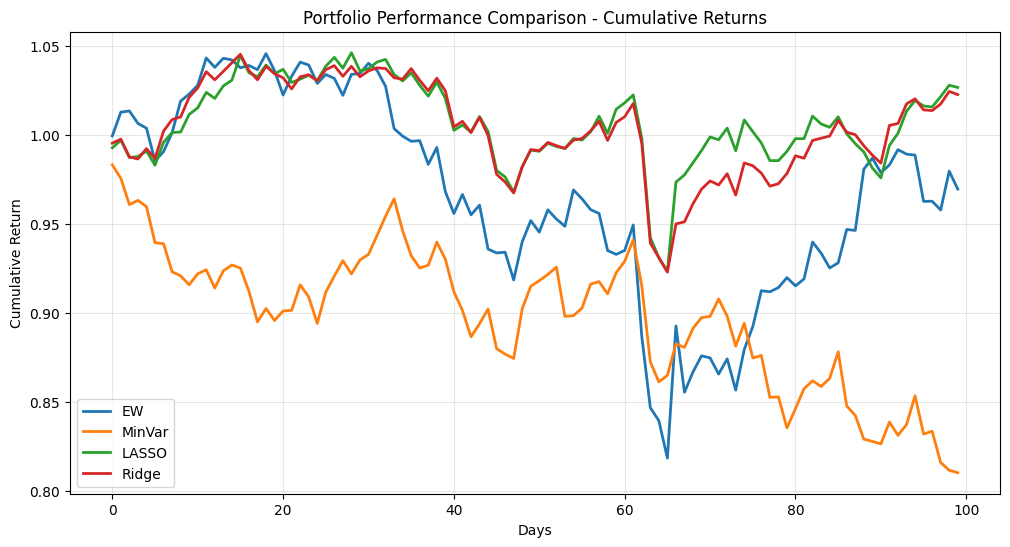

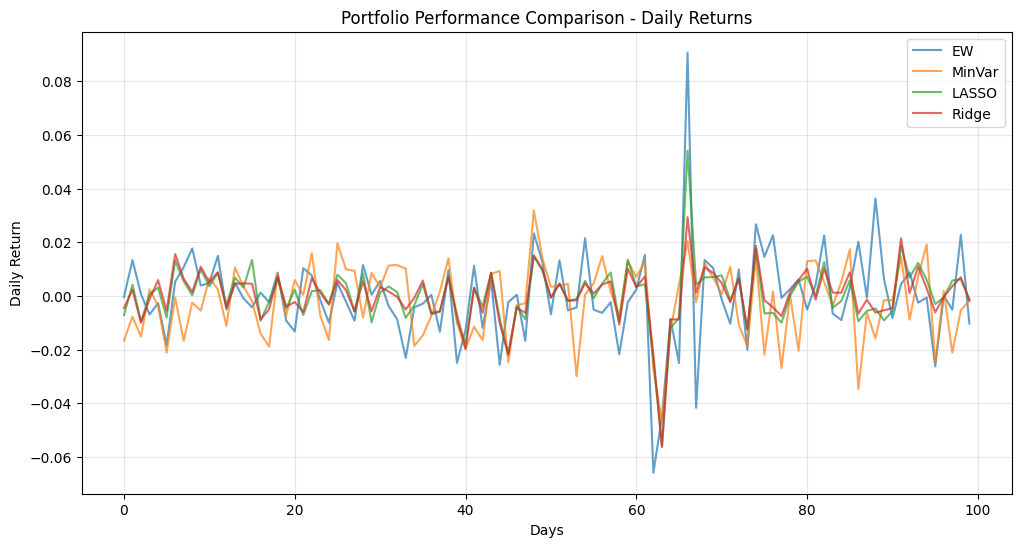

Analysis complete!


In [ ]:
# STEP 6: VISUALIZATION (REPLACEMENT)

plt.figure(figsize=(12, 6))
for col in ret_df.columns:
    plt.plot(np.cumprod(1 + ret_df[col].values), label=col, linewidth=2)
plt.title('Portfolio Performance Comparison - Cumulative Returns')
plt.xlabel('Days')
plt.ylabel('Cumulative Return')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(12, 6))
for col in ret_df.columns:
    plt.plot(ret_df[col].values, label=col, alpha=0.7)
plt.title('Portfolio Performance Comparison - Daily Returns')
plt.xlabel('Days')
plt.ylabel('Daily Return')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()
